# CAES mini-project: system design and simulation

Compressed Air Energy Storage (CAES) stores electricity by compressing air into a reservoir. During discharge, the air is heated and expanded through a turbine to produce electricity. The project compares how compression heat management and reservoir design affect performance.

## System variants

The six variants combine three architectures with two reservoir types:

| Architecture | Constant-volume reservoir | Constant-pressure reservoir |
|---|---|---|
| Single-stage compression and expansion; compression heat rejected | 1a | 1b |
| Single-stage with thermal energy storage (TES) | 2a | 2b |
| Two-stage compression with intercooling and two-stage expansion with reheat; no TES | 3a | 3b |

A constant-volume reservoir operates between 16 bar and a minimum pressure of 8 bar, so its pressure falls during discharge. A constant-pressure reservoir remains at 16 bar while its volume varies. Variants 2a and 2b store compression heat in a hot-water TES and reuse it to preheat discharge air before combustion. Variants 3a and 3b use equal pressure-ratio stages; intercooling heat is rejected, and fuel reheats the air before each turbine stage.

## Common specification

- Working fluid: real-gas air (CoolProp).
- Ambient conditions: 15°C and 1.013 bar.
- Maximum storage pressure: 16 bar; minimum pressure for constant-volume storage: 8 bar.
- Target output: 1 MW at the turbine/generator shaft for 4 hours (4 MWh per cycle); charge duration is also 4 hours.
- Compressor isentropic efficiency: 0.85; turbine isentropic efficiency: 0.88.
- Mechanical/generator efficiency: 0.98.
- Turbine inlet temperature: 550°C. Combustion is represented as heat addition to reach this temperature, without modelling combustion chemistry.
- Cooler and TES return pinches: 10 K. Air is cooled towards ambient temperature plus the cooler pinch before storage.
- The reservoir is treated as a uniform 0D store. Stored air is assumed to return to ambient temperature before discharge and remain near ambient during discharge.

## Performance and design tasks

Use the same two-step workflow for the selected variant:

1. **Design:** size the required components, heat exchangers, and storage volume for the common output target.
2. **Simulation:** model a complete charge/discharge cycle and evaluate performance.

The common round-trip metric values fuel at its electrical equivalent:

\[
\eta = \frac{W_{\mathrm{turbine}}}{W_{\mathrm{compressor}} + \eta_f Q_{\mathrm{combustion}}},
\qquad \eta_f = 0.40.
\]

Compare round-trip efficiency, storage volume, heat-exchanger areas, maximum temperatures, and the electrical/fuel input split. Include energy (and optionally exergy) balances, identify major losses, and quantify at least one proposed performance improvement. The final comparison should show how thermal storage, staging, and reservoir type affect these results.

Here are some sources i used to return to later (soso)

Return to Gas Turbines EENG4 S8 for compressor eq and details (soso)

Paper on which sile will the pinch temp be occuring based on the Cc and Ch (LMTD) method. https://sci-hub.fr/10.1016/B978-008042839-0/50008-2 (soso)

Also return to EENG3 S6 Lec 4 for counter flow details and eq (soso)

In [125]:
# --- imports ---
from pathlib import Path
import sys

for root in (Path.cwd(), *Path.cwd().parents):
    for package_root in (root, root / "caldis-0.3.0"):
        if (package_root / "caldis" / "__init__.py").is_file():
            sys.path.insert(0, str(package_root))
            break
    else:
        continue
    break

import numpy as np
import caldis
from CoolProp.CoolProp import PropsSI
from caldis.core.system import System
from caldis.components import FluidBoundary
from caldis.components import Compressor
from caldis.fluids import CoolPropBackend
from caldis.components import SizingHX
from caldis.components import CombustionChamber
from caldis.components import Turbine
from caldis.components.vessels.tank import TankConstP
from caldis.solvers import dynamic
from caldis.solvers import solve, simulate


Initilize paramaters

Ambient Air --> Compressor --> Cooler --> Air Storage --> Combustor --> Turbine --> Exhuast

In [126]:
# --- system definition ---
T0 = 15 + 273.15      # 288.15 K
P0 = 1.013e5          # 1.013 bar
Eta_ISC = 0.85
Eta_IST = 0.88        # 0.88 per PDF specification (not 0.85!)
Eta_Mech = 0.98

Pmax = 16e5           # 16 bar
Ttit = 550 + 273.15   # 823.15 K
Eta_Fuel = 0.4
W_target = 1.0e6      # 1 MW shaft power target

Paramters to assume

In [127]:
# A1: First we define a mass flow rate
Mdot_air=1 #kg/s
Mdot_water=1 #kg/s

# Air storage sizing
Mdot_discharge_start = 3  # kg/s
Mass = Mdot_discharge_start * 3600 * 4  # kg stored for 4 hours

rho_tank_initial = PropsSI(
    'D', 'T', T0, 'P', Pmax, 'Air'
)  # kg/m3

V_tank_initial = Mass / rho_tank_initial  # m3


# A2: We define a guess for the water outlet temperature
T_water_out_Guess = 100 + 273.15 #K This is an assumption cuz it must be less than 400 and more than T0+Tpinch

# A3: We define the backend for the fluids which is the film convection coefficients
# The heat exchanger is a counter flow heat exchanger with water on one side and air on the other side. 
# The heat transfer coefficients are based on the type of fluid and the flow conditions. Typical values are:
#   forced convection in gas (air): 50–250 W/m²/K
#   forced convection in liquid (water): 500–10000 W/m²/K
h_film_air   = 100.0    # W/m²/K  (air side)
h_film_water = 3000.0   # W/m²/K  (water side)

T_out_comp_guess = 350 + 273.15 #K This is an assumption cuz it must be less than Ttit and more than T0

Ratio_Area_cold_to_hot = 0.5 # This is an assumption, it can be changed to see the effect on the performance of the system


In [128]:
# ==============================================================================
# Sizing and Thermal Modeling of Cylindrical SS304 Storage Tank
# ==============================================================================

# Material Properties: Stainless Steel 304
Density_Steel_304 = 7955.0  # kg/m3
Cp_Tank = 500.0             # J/(kg*K)
k_steel = 16.0              # W/(m*K) (thermal conductivity of SS304)

# Geometry of Cylinder
Diameter_Tank_out = 8.0     # m (outer diameter)
Thickness_wall = 0.12       # m (wall thickness)

r_out = Diameter_Tank_out / 2.0             # 4.0 m
r_in = r_out - Thickness_wall               # 3.88 m
Diameter_Tank_in = 2.0 * r_in               # 7.76 m
r_mid = (r_out + r_in) / 2.0                # 3.94 m

# Cross-sectional areas
Area_Tank_in_cs = np.pi * (r_in ** 2)                  # m2 (internal fluid area)
Area_Tank_Shell_cs = np.pi * (r_out ** 2 - r_in ** 2)  # m2 (metal shell cross section)

# Length of Tank required to hold initial air volume
Length_Tank = V_tank_initial / Area_Tank_in_cs         # m (~39.9 m)

# Heat transfer surface areas (lateral cylinder area)
Area_Tank_in_surf = 2.0 * np.pi * r_in * Length_Tank   # m2 (~973.8 m2)
Area_Tank_out_surf = 2.0 * np.pi * r_out * Length_Tank # m2 (~1003.9 m2)

# Mass and Thermal Heat Capacity of Wall (Cwall)
Volume_Tank_Shell = Area_Tank_Shell_cs * Length_Tank
Mass_Tank = Density_Steel_304 * Volume_Tank_Shell      # kg (~943,900 kg)
Cwall = Mass_Tank * Cp_Tank                            # J/K (~4.72e8 J/K)



#  Convection coefficient inside tank for air at 16 bar:

h_in = 10.0  # W/(m2*K)
R_conv_in = 1.0 / (h_in * Area_Tank_in_surf)           # K/W (~2.05e-5)

# Coupling conductance between wall lumped node (at r_mid) and inner fluid:
# R_coupling = R_conv_in + R_wall_inner_half
R_coupling = R_conv_in + (np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank))
UA_wall = 1.0 / R_coupling                             # W/K (~41,100 W/K)

# Expansion boundary heat replenishment (P * dV/dt = mdot * P / rho)
# Needed to offset constant-pressure volume contraction cooling:
Q_boundary_work = Mdot_discharge_start * (Pmax / rho_tank_initial)  # ~206,500 W

print(f"Tank Length:         {Length_Tank:.2f} m")
print(f"Internal Area:       {Area_Tank_in_surf:.2f} m²")
print(f"Tank Shell Mass:     {Mass_Tank:.1f} kg")
print(f"Cwall:               {Cwall:.3e} J/K")
print(f"R_wall (conduction): {R_wall:.3e} K/W")
print(f"UA_wall:             {UA_wall:.1f} W/K")
print(f"Q_boundary_work:     {Q_boundary_work:.1f} W")

Tank Length:         46.93 m
Internal Area:       1144.21 m²
Tank Shell Mass:     1109150.2 kg
Cwall:               5.546e+08 J/K
R_wall (conduction): 6.455e-06 K/W
UA_wall:             11031.5 W/K
Q_boundary_work:     246640.1 W


In [129]:
# --- Fluid Backends ---
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")

# Thermodynamic properties at storage
h_tank = PropsSI("H", "T", T0, "P", Pmax, "Air")
rho_tank = PropsSI("D", "T", T0, "P", Pmax, "Air")  # ~19.462 kg/m³

# Exact discharge air mass flow rate calculation:
# Turbine inlet pressure with 4% combustor drop: 16 bar * 0.96 = 15.36 bar
h_turb_in = PropsSI("H", "T", Ttit, "P", Pmax * 0.96, "Air")
s_turb_in = PropsSI("S", "T", Ttit, "P", Pmax * 0.96, "Air")
h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")
w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)  # Specific work [J/kg]

Mdot_discharge = W_target / w_sp                       # ~2.512 kg/s
Mass_total = Mdot_discharge * (4 * 3600)                # ~36,170 kg
V_tank_initial = (Mass_total / rho_tank) * 1.005        # ~1889 m³ (0.5% margin)



# --- Component Instantiation ---
Source = FluidBoundary(name="Source", T=T0, mdot=0, backend=be_air)
Tank = TankConstP(
    name="Tank",
    backend=be_air,
    p=Pmax,
    h_init=h_tank,
    V_init=V_tank_initial,
    C_wall=Cwall,
    T_wall_init=T0,
    UA_wall=UA_wall,
    Q_heater=0
)
Comb = CombustionChamber(
    name="Comb",
    backend_air=be_air,
    backend_fuel=be_fuel,
    LHV=50e6,
    eta_comb=1.0,
    dp_rel=0.04
)
Fuel_in = FluidBoundary(name="Fuel_in", p=P0, T=T0, backend=be_fuel)
Turbine = Turbine(name="Turbine", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
Exhaust = FluidBoundary(name="Exhaust", p=P0, backend=be_air)

In [130]:
# --- System wiring ---
sys_ = System("Discharge_Cycle")
sys_.add(Source, Tank, Turbine, Comb, Fuel_in, Exhaust)

sys_.connect(Source.port, Tank.inl)
sys_.connect(Tank.out, Comb.air_in)
sys_.connect(Fuel_in.port, Comb.fuel_in)
sys_.connect(Comb.gas_out, Turbine.inl)
sys_.connect(Turbine.out, Exhaust.port)

# --- Constraints ---
# 1. Combustor reaches TIT = 550°C
sys_.add_constraint(
    lambda: be_air.T(Comb.gas_out.p, Comb.gas_out.h) - Ttit,
    "TIT_550C"
)

# 2. Turbine delivers 1 MW net shaft power
sys_.add_constraint(
    lambda: Eta_Mech * Turbine.inl.mdot * (Turbine.inl.h - Turbine.out.h) - W_target,
    "Wdot_1MW"
)

# --- Start Hints ---
sys_.set_start_port(Tank.out,      p=Pmax,        T=T0,           mdot=-2.6)
sys_.set_start_port(Fuel_in.port,  p=P0,          T=T0,           mdot=-0.0286)
sys_.set_start_port(Comb.air_in,   p=Pmax,        T=T0,           mdot=2.6)
sys_.set_start_port(Comb.gas_out,  p=Pmax * 0.96, T=Ttit,         mdot=-2.6)
sys_.set_start_port(Turbine.inl,   p=Pmax * 0.96, T=Ttit,         mdot=2.6)
sys_.set_start_port(Turbine.out,   p=P0,          T=250+273.15, mdot=-2.6)
sys_.set_start_port(Exhaust.port,  p=P0,          T=250+273.15, mdot=2.6)
sys_.init_starts()

# --- Run 4-Hour Dynamic Simulation ---
results = simulate(sys_, t_end=4 * 3600, dt=240, init="consistent", progress=True)

# --- Inspect Results ---
df = results.to_dataframe()
print("\n=== Discharge Simulation Finished Successfully ===")
print(f"Air mass flow rate:       {abs(df['Tank.fluid.out.mdot'].iloc[0]):.4f} kg/s")
print(f"Fuel mass flow rate:      {abs(df['Fuel_in.port.mdot'].iloc[0]):.5f} kg/s")
print(f"Turbine power delivered:  {df['Turbine.Wdot'].iloc[0]/1e6:.4f} MW")
print(f"Starting Tank Volume:     {df['Tank.V'].iloc[0]:.1f} m³")
print(f"Final Tank Volume (4h):   {df['Tank.V'].iloc[-1]:.1f} m³")

✓ DOF: square (35 unknowns)
✓ start point: evaluable
  simulate  [  60/60]  t=14400.0s  |F|=5.0e-09

=== Discharge Simulation Finished Successfully ===
Air mass flow rate:       2.5117 kg/s
Fuel mass flow rate:      0.02864 kg/s
Turbine power delivered:  1.0000 MW
Starting Tank Volume:     1889.1 m³
Final Tank Volume (4h):   28.8 m³


Discharge results (provisional Part 5 answers)
1. Discharge duration:             4.00 h
2. Mean turbine shaft output:      0.980 MW
3. Turbine shaft energy delivered: 3.920 MWh
4. Fuel heat supplied:             21.240 GJ
5. Fuel electrical-equivalent:     2.360 MWh
6. Air discharged:                 36,157 kg
7. Fuel consumed:                  424.8 kg
8. Tank volume:                    1,889.1 → 28.8 m³
9. Tank pressure range:            16.00–16.00 bar
10. Tank air temperature range:    -6.4–15.0 °C
Note: Round-trip efficiency requires compressor energy from the charge simulation.


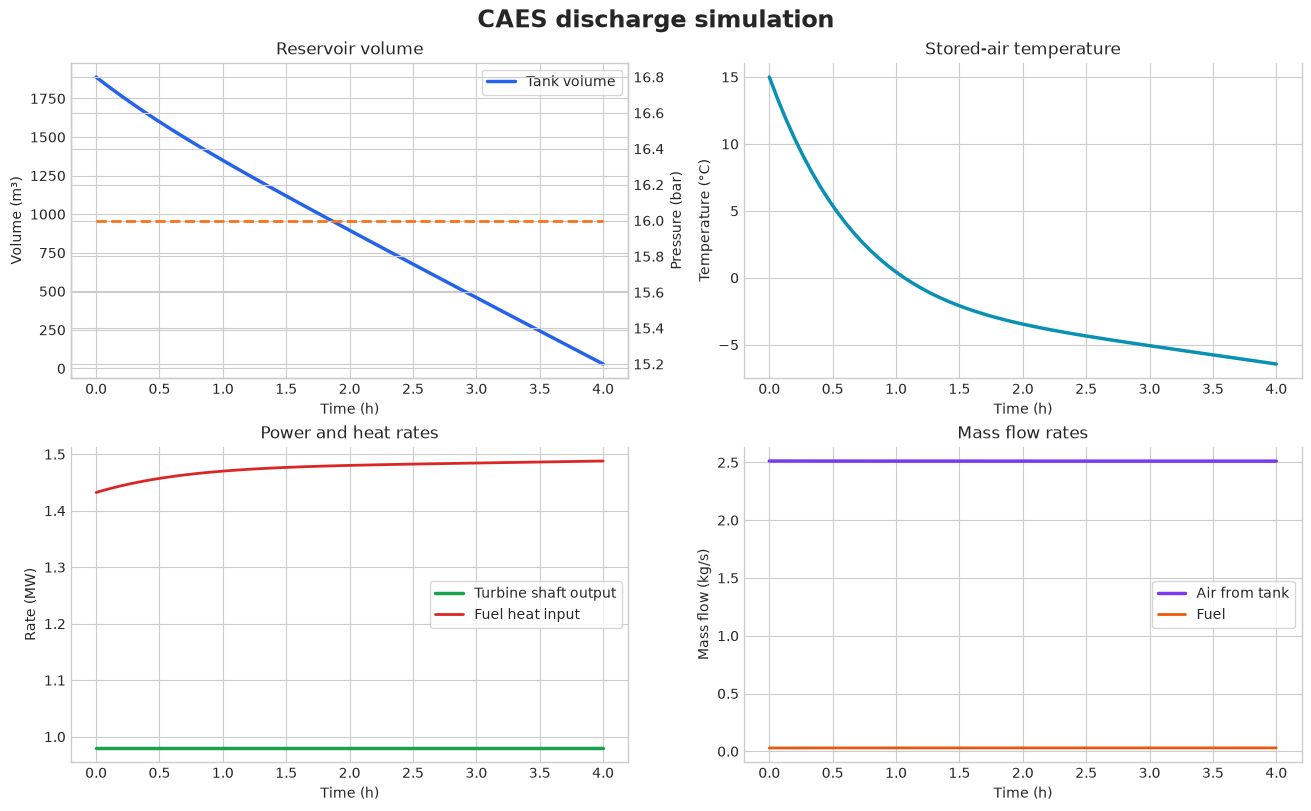

In [131]:
import matplotlib.pyplot as plt

# Extract simulation data
time_s = df["time"].to_numpy()
time_h = time_s / 3600

air_flow = df["Tank.fluid.out.mdot"].abs().to_numpy()
fuel_flow = df["Fuel_in.port.mdot"].abs().to_numpy()
shaft_power = (Eta_Mech * df["Turbine.Wdot"]).to_numpy()
fuel_heat_rate = df["Comb.Qdot_fuel"].to_numpy()

# Integrate rates over the simulated discharge
turbine_energy_J = np.trapezoid(shaft_power, time_s)
fuel_energy_J = np.trapezoid(fuel_heat_rate, time_s)
air_mass_kg = np.trapezoid(air_flow, time_s)
fuel_mass_kg = np.trapezoid(fuel_flow, time_s)

volume = df["Tank.V"].to_numpy()
tank_temp_C = df["Tank.fluid.T"].to_numpy() - 273.15
tank_pressure_bar = df["Tank.fluid.out.p"].to_numpy() / 1e5

print("Discharge results (provisional Part 5 answers)")
print(f"1. Discharge duration:             {time_h[-1]:.2f} h")
print(f"2. Mean turbine shaft output:      {turbine_energy_J / (time_s[-1] - time_s[0]) / 1e6:.3f} MW")
print(f"3. Turbine shaft energy delivered: {turbine_energy_J / 3.6e9:.3f} MWh")
print(f"4. Fuel heat supplied:             {fuel_energy_J / 1e9:.3f} GJ")
print(f"5. Fuel electrical-equivalent:     {Eta_Fuel * fuel_energy_J / 3.6e9:.3f} MWh")
print(f"6. Air discharged:                 {air_mass_kg:,.0f} kg")
print(f"7. Fuel consumed:                  {fuel_mass_kg:,.1f} kg")
print(f"8. Tank volume:                    {volume[0]:,.1f} → {volume[-1]:,.1f} m³")
print(f"9. Tank pressure range:            {tank_pressure_bar.min():.2f}–{tank_pressure_bar.max():.2f} bar")
print(f"10. Tank air temperature range:    {tank_temp_C.min():.1f}–{tank_temp_C.max():.1f} °C")
print("Note: Round-trip efficiency requires compressor energy from the charge simulation.")

# Plot simulation trends
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
fig.suptitle("CAES discharge simulation", fontsize=17, fontweight="bold")

ax = axes[0, 0]
ax.plot(time_h, volume, color="#2563eb", linewidth=2.5, label="Tank volume")
ax.set(title="Reservoir volume", xlabel="Time (h)", ylabel="Volume (m³)")
ax2 = ax.twinx()
ax2.plot(time_h, tank_pressure_bar, color="#f97316", linewidth=2, linestyle="--", label="Pressure")
ax2.set_ylabel("Pressure (bar)")
ax.legend(loc="best", frameon=True)

ax = axes[0, 1]
ax.plot(time_h, tank_temp_C, color="#0891b2", linewidth=2.5)
ax.set(title="Stored-air temperature", xlabel="Time (h)", ylabel="Temperature (°C)")

ax = axes[1, 0]
ax.plot(time_h, shaft_power / 1e6, color="#16a34a", linewidth=2.5, label="Turbine shaft output")
ax.plot(time_h, fuel_heat_rate / 1e6, color="#dc2626", linewidth=2, label="Fuel heat input")
ax.set(title="Power and heat rates", xlabel="Time (h)", ylabel="Rate (MW)")
ax.legend(frameon=True)

ax = axes[1, 1]
ax.plot(time_h, air_flow, color="#7c3aed", linewidth=2.5, label="Air from tank")
ax.plot(time_h, fuel_flow, color="#ea580c", linewidth=2, label="Fuel")
ax.set(title="Mass flow rates", xlabel="Time (h)", ylabel="Mass flow (kg/s)")
ax.legend(frameon=True)

for ax in axes.flat:
    ax.spines["top"].set_visible(False)

plt.show()

In [132]:
#sys_.structure()
Tank.describe()

=== TankConstP('Tank') ===
  ports (p [bar], mdot [kg/s], T [°C]):
  outputs:
    Q                = 189933
    T_fluid          = 266.711
    T_wall           = 283.929
    V                = 28.7912
=== ControlVolumeP('Tank.fluid') ===
  variables:
    M                = 607.838
    U                = 1.90109e+08
    V                = 28.7912
    h                = 388549
  ports (p [bar], mdot [kg/s], T [°C]):
    inl        p=16.000  mdot=+0  h=410.7kJ/kg  T=15.00
    out        p=16.000  mdot=-2.511  h=388.5kJ/kg  T=-6.44
  outputs:
    rho              = 21.1119
    T                = 266.711
    x                = 2
    V                = 28.7912
=== ThermalMass('Tank.wall') ===
  variables:
    T                = 283.929
  ports (p [bar], mdot [kg/s], T [°C]):
  outputs:
    Qdot_ext         = -189933


{'variables': {},
 'ports': {},
 'outputs': {'Q': np.float64(189933.414415674),
  'T_fluid': 266.7114754184114,
  'T_wall': 283.9287691855138,
  'V': 28.7911886741061}}

In [133]:
Comb.describe()

Turbine.describe()

Exhaust.describe()

=== CombustionChamber('Comb') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    air_in     p=16.000  mdot=+2.511  h=388.5kJ/kg  T=-6.44
    fuel_in    p=1.013  mdot=+0.02976  h=887.7kJ/kg  T=15.00
    gas_out    p=15.360  mdot=-2.54  h=974.4kJ/kg  T=550.00
  outputs:
    Qdot_fuel        = 1.48796e+06
    Qdot_released    = 1.48796e+06
    AFR              = 84.3652
    excess_air       = 4.90495
=== Turbine('Turbine') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    inl        p=15.360  mdot=+2.54  h=974.4kJ/kg  T=550.00
    out        p=1.013  mdot=-2.54  h=572.8kJ/kg  T=171.59
  outputs:
    Wdot             = 1e+06
    Wdot_is          = 1.13636e+06
    pressure_ratio   = 15.1629
    h_out_s          = 517981
    T_out_s          = 390.852
=== FluidBoundary('Exhaust') ===
  ports (p [bar], mdot [kg/s], T [°C]):
    port       p=1.013  mdot=+2.54  h=572.8kJ/kg  T=171.59


{'variables': {},
 'ports': {'port': {'p': 101300.0,
   'mdot': 2.5403929977988047,
   'h': 572755.1082475686}},
 'outputs': {}}